
========== ORIGINAL DATASET ==========
Student  Marks
      A     45
      B     50
      C     52
      D     48
      E     55
      F     60
      G     58
      H     62
      I     65
      J     59
      K     61
      L     57
      M     63
      N     56
      O     54
      P     51
      Q     49
      R     95
      S    100
      T      5


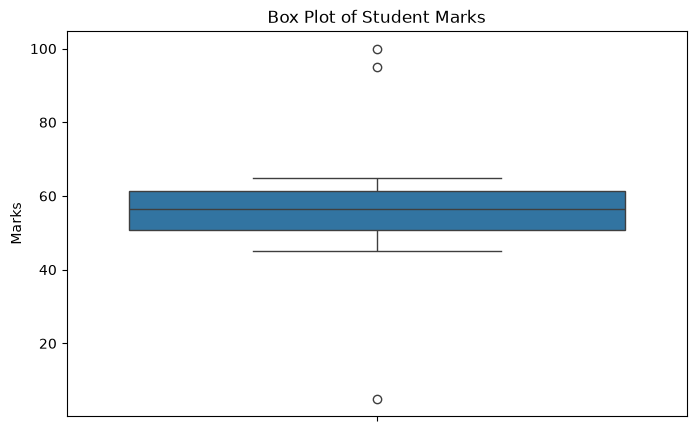


========== IQR METHOD ==========
Q1 = 50.75
Q3 = 61.25
IQR = 10.5
Lower Limit = 35.0
Upper Limit = 77.0

Outliers detected using IQR:
Student  Marks
      R     95
      S    100
      T      5


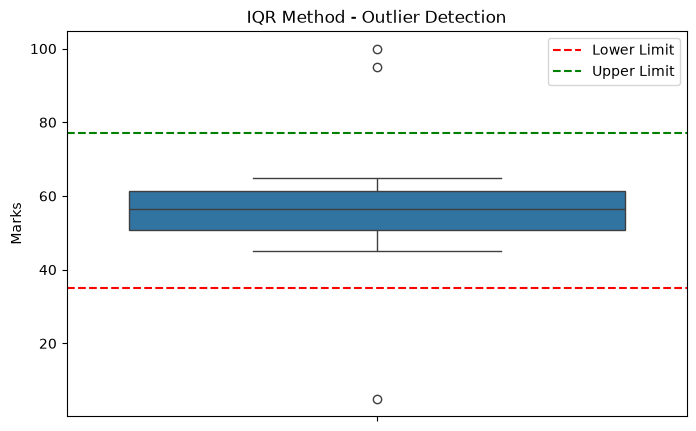


========== IQR CAPPING ==========
Student  Marks  Marks_IQR_Capped
      A     45                45
      B     50                50
      C     52                52
      D     48                48
      E     55                55
      F     60                60
      G     58                58
      H     62                62
      I     65                65
      J     59                59
      K     61                61
      L     57                57
      M     63                63
      N     56                56
      O     54                54
      P     51                51
      Q     49                49
      R     95                77
      S    100                77
      T      5                35


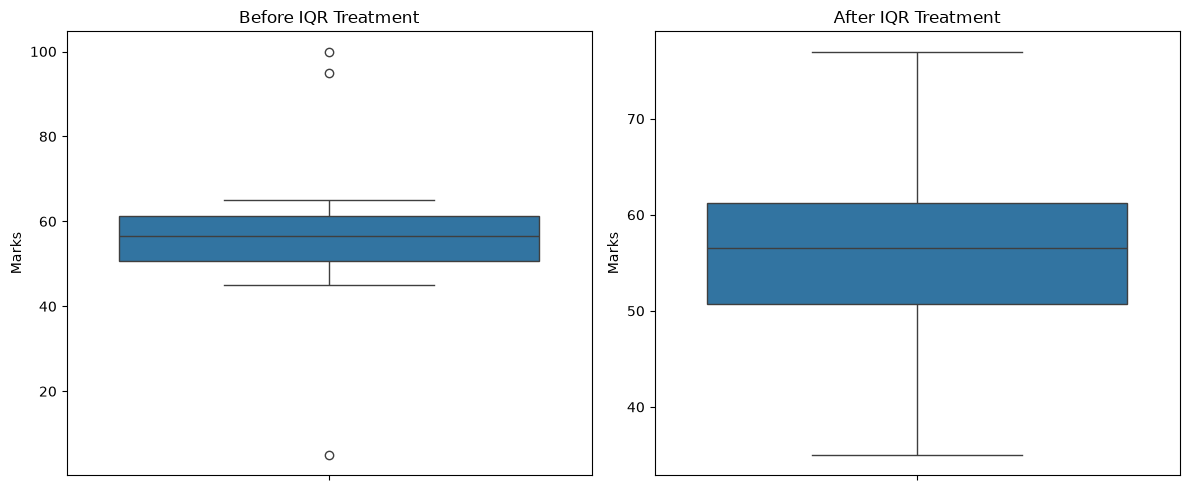


After IQR capping, extreme values are replaced
with the lower or upper IQR boundary.

========== Z-SCORE METHOD ==========
Student  Marks   Z_score
      A     45 -0.676200
      B     50 -0.400200
      C     52 -0.289800
      D     48 -0.510600
      E     55 -0.124200
      F     60  0.151800
      G     58  0.041400
      H     62  0.262200
      I     65  0.427800
      J     59  0.096600
      K     61  0.207000
      L     57 -0.013800
      M     63  0.317400
      N     56 -0.069000
      O     54 -0.179400
      P     51 -0.345000
      Q     49 -0.455400
      R     95  2.083800
      S    100  2.359799
      T      5 -2.884199

Outliers detected using Z-score (|Z| > 3):
No outliers detected using the Z-score rule.

Z-score outlier status:
Student  Marks   Z_score  Z_Outlier
      A     45 -0.676200      False
      B     50 -0.400200      False
      C     52 -0.289800      False
      D     48 -0.510600      False
      E     55 -0.124200      False
      F     60  0.151

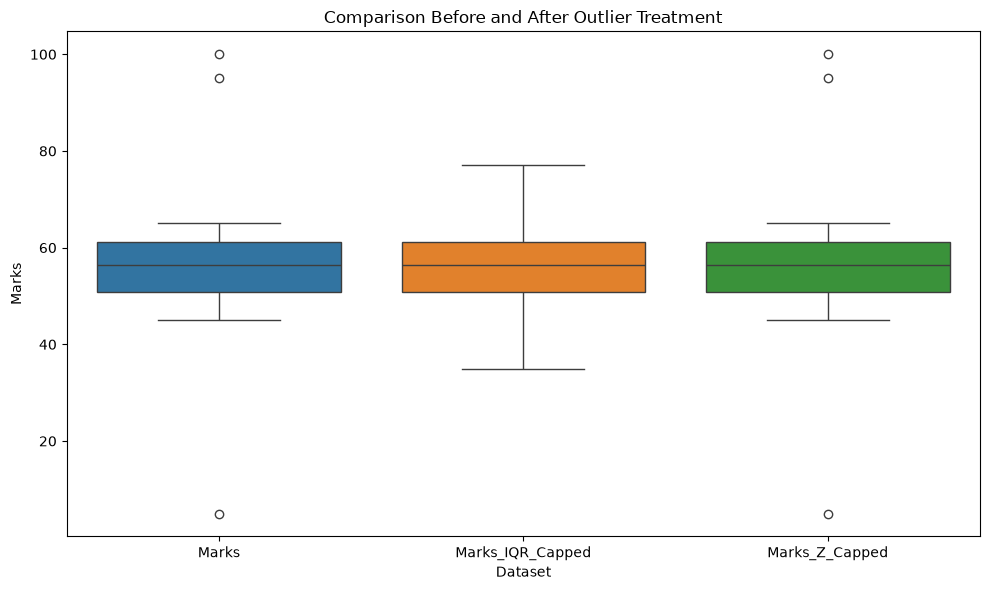


Program executed successfully!


In [3]:

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 2. Create a sample dataset
data = {
    'Student': [
        'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J',
        'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T'
    ],
    'Marks': [
        45, 50, 52, 48, 55, 60, 58, 62, 65, 59,
        61, 57, 63, 56, 54, 51, 49, 95, 100, 5
    ]
}

df = pd.DataFrame(data)

print("\n========== ORIGINAL DATASET ==========")
print(df.to_string(index=False))

# 3. Visualize the original data using a box plot
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])
plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")
plt.show()

# 4. Detect outliers using the IQR method

# Step 1: Calculate Q1 and Q3
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

print("\n========== IQR METHOD ==========")
print("Q1 =", Q1)
print("Q3 =", Q3)

# Step 2: Calculate IQR
IQR = Q3 - Q1
print("IQR =", IQR)

# Step 3: Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

# Step 4: Identify outliers
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

print("\nOutliers detected using IQR:")
print(outliers_iqr.to_string(index=False))

# 5. Visualize IQR limits and outliers
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['Marks'])
plt.axhline(
    lower_limit, color='red', linestyle='--',
    label='Lower Limit'
)
plt.axhline(
    upper_limit, color='green', linestyle='--',
    label='Upper Limit'
)
plt.title("IQR Method - Outlier Detection")
plt.ylabel("Marks")
plt.legend()
plt.show()

# 6. IQR outlier treatment - Capping
df['Marks_IQR_Capped'] = df['Marks'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("\n========== IQR CAPPING ==========")
print(df[['Student', 'Marks', 'Marks_IQR_Capped']].to_string(index=False))

# 7. Visualize before and after IQR treatment
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Marks'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")
axes[0].set_ylabel("Marks")

sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")
axes[1].set_ylabel("Marks")

plt.tight_layout()
plt.show()

print("\nAfter IQR capping, extreme values are replaced")
print("with the lower or upper IQR boundary.")

# 8. Detect outliers using the Z-score method
df['Z_score'] = stats.zscore(df['Marks'])

print("\n========== Z-SCORE METHOD ==========")
print(df[['Student', 'Marks', 'Z_score']].to_string(index=False))

# 9. Identify Z-score outliers
df['Z_Outlier'] = abs(df['Z_score']) > 3

z_outliers = df[df['Z_Outlier']]

print("\nOutliers detected using Z-score (|Z| > 3):")

if z_outliers.empty:
    print("No outliers detected using the Z-score rule.")
else:
    print(z_outliers[['Student', 'Marks', 'Z_score']].to_string(index=False))

print("\nZ-score outlier status:")
print(df[['Student', 'Marks', 'Z_score', 'Z_Outlier']].to_string(index=False))

# 10. Z-score outlier treatment - Capping
mean = df['Marks'].mean()

# Use population standard deviation to match scipy.stats.zscore
std = df['Marks'].std(ddof=0)

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("\n========== Z-SCORE CAPPING ==========")
print("Mean =", mean)
print("Standard Deviation =", std)
print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print("\nOriginal marks and Z-score capped marks:")
print(df[['Student', 'Marks', 'Marks_Z_Capped']].to_string(index=False))

# 11. Compare original and treated data
print("\n========== FINAL COMPARISON ==========")
print(
    df[['Student', 'Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']]
    .to_string(index=False)
)

# Visualize all three versions
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']]
)

plt.title("Comparison Before and After Outlier Treatment")
plt.ylabel("Marks")
plt.xlabel("Dataset")
plt.tight_layout()
plt.show()

print("\nProgram executed successfully!")
